In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

from pathlib import Path
from collections import Counter

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Locate project data folder
project_dir = Path.cwd()

if not (project_dir / "data").exists():
    project_dir = project_dir.parent

data_dir = project_dir / "data"

# Load three datasets
files = [
    "amazon_cells_labelled.txt",
    "imdb_labelled.txt",
    "yelp_labelled.txt"
]

dataframes = []

for file in files:
    df_part = pd.read_csv(
        data_dir / file,
        sep="\t",
        header=None,
        names=["sentence", "label"]
    )

    df_part["source"] = file.replace("_labelled.txt", "")
    dataframes.append(df_part)

df = pd.concat(dataframes, ignore_index=True)

print("Dataset shape:", df.shape)
print("\nFirst five records:")
print(df.head())

print("\nSentiment distribution:")
print(df["label"].value_counts())

Dataset shape: (2748, 3)

First five records:
                                            sentence  label        source
0  So there is no way for me to plug it in here i...      0  amazon_cells
1                        Good case, Excellent value.      1  amazon_cells
2                             Great for the jawbone.      1  amazon_cells
3  Tied to charger for conversations lasting more...      0  amazon_cells
4                                  The mic is great.      1  amazon_cells

Sentiment distribution:
label
1    1386
0    1362
Name: count, dtype: int64


In [ ]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()


# Apply preprocessing
df["clean_text"] = df["sentence"].apply(clean_text)

# Compare original and cleaned text
comparison = df[["sentence", "clean_text", "label"]]

print(comparison.head(10).to_string(index=False))

                                                                                                       sentence                                                                                                    clean_text  label
                             So there is no way for me to plug it in here in the US unless I go by a converter.                             so there is no way for me to plug it in here in the us unless i go by a converter      0
                                                                                    Good case, Excellent value.                                                                                     good case excellent value      1
                                                                                         Great for the jawbone.                                                                                         great for the jawbone      1
                                Tied to charger for conversations lasting more than 

In [ ]:
print("POSITIVE REVIEWS")
print(
    df[df["label"] == 1]["sentence"]
    .head(5)
    .to_string(index=False)
)

print("\nNEGATIVE REVIEWS")
print(
    df[df["label"] == 0]["sentence"]
    .head(5)
    .to_string(index=False)
)

POSITIVE REVIEWS
                Good case, Excellent value.
                     Great for the jawbone.
                          The mic is great.
If you are Razr owner...you must have this!
            And the sound quality is great.

NEGATIVE REVIEWS
So there is no way for me to plug it in here in...
Tied to charger for conversations lasting more ...
I have to jiggle the plug to get it to line up ...
If you have several dozen or several hundred co...
               Needless to say, I wasted my money.


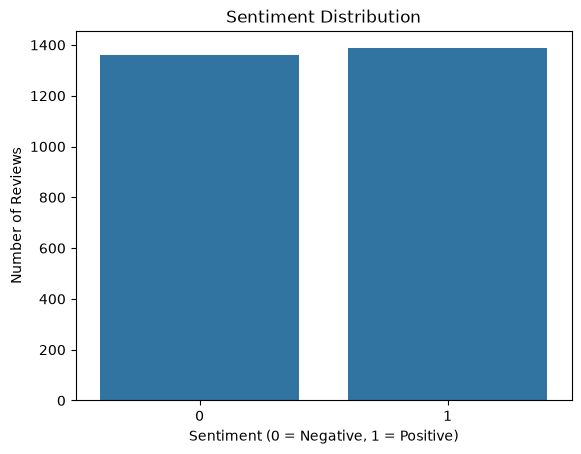

In [ ]:
sns.countplot(data=df, x="label")

plt.title("Sentiment Distribution")
plt.xlabel("Sentiment (0 = Negative, 1 = Positive)")
plt.ylabel("Number of Reviews")

plt.show()

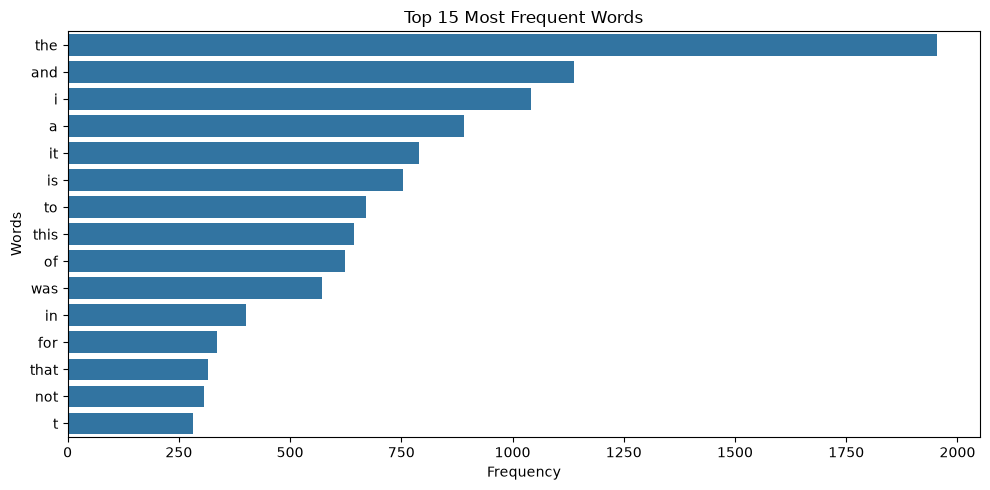

In [ ]:
all_words = " ".join(df["clean_text"]).split()

word_counts = Counter(all_words)

top_words = word_counts.most_common(15)

words = [word for word, count in top_words]
counts = [count for word, count in top_words]

plt.figure(figsize=(10, 5))
sns.barplot(x=counts, y=words)

plt.title("Top 15 Most Frequent Words")
plt.xlabel("Frequency")
plt.ylabel("Words")

plt.tight_layout()
plt.show()

In [ ]:
positive_text = " ".join(
    df[df["label"] == 1]["clean_text"]
)

negative_text = " ".join(
    df[df["label"] == 0]["clean_text"]
)

positive_words = Counter(positive_text.split())
negative_words = Counter(negative_text.split())

print("Top Positive Review Words:")
print(positive_words.most_common(10))

print("\nTop Negative Review Words:")
print(negative_words.most_common(10))

Top Positive Review Words:
[('the', 960), ('and', 665), ('i', 477), ('a', 451), ('is', 397), ('it', 363), ('this', 318), ('to', 288), ('of', 287), ('was', 248)]

Top Negative Review Words:
[('the', 993), ('i', 564), ('and', 473), ('a', 440), ('it', 426), ('to', 382), ('is', 357), ('of', 337), ('this', 325), ('was', 323)]


In [ ]:
X = df["clean_text"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 2198
Testing samples: 550


In [ ]:
vectorizer = CountVectorizer()

X_train_bow = vectorizer.fit_transform(X_train)
X_test_bow = vectorizer.transform(X_test)

print("Training BOW shape:", X_train_bow.shape)
print("Testing BOW shape:", X_test_bow.shape)

print("\nSample vocabulary:")
print(vectorizer.get_feature_names_out()[:20])

Training BOW shape: (2198, 4439)
Testing BOW shape: (550, 4439)

Sample vocabulary:
['aailiyah' 'abandoned' 'abhor' 'ability' 'able' 'abound' 'about' 'above'
 'abroad' 'absolute' 'absolutel' 'absolutely' 'absolutley' 'abstruse'
 'abysmal' 'academy' 'accept' 'acceptable' 'access' 'accessable']


In [ ]:
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_model.fit(X_train_bow, y_train)

lr_predictions = lr_model.predict(X_test_bow)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [ ]:
svm_model = LinearSVC(
    max_iter=5000,
    random_state=42
)

svm_model.fit(X_train_bow, y_train)

svm_predictions = svm_model.predict(X_test_bow)

print("SVM training completed!")

SVM training completed!


In [ ]:
print("LOGISTIC REGRESSION PERFORMANCE")

print("Accuracy:", accuracy_score(y_test, lr_predictions))
print("Precision:", precision_score(y_test, lr_predictions))
print("Recall:", recall_score(y_test, lr_predictions))
print("F1 Score:", f1_score(y_test, lr_predictions))

print("\nClassification Report:")
print(classification_report(y_test, lr_predictions))

LOGISTIC REGRESSION PERFORMANCE
Accuracy: 0.8218181818181818
Precision: 0.8403041825095057
Recall: 0.7978339350180506
F1 Score: 0.8185185185185185

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.85      0.82       273
           1       0.84      0.80      0.82       277

    accuracy                           0.82       550
   macro avg       0.82      0.82      0.82       550
weighted avg       0.82      0.82      0.82       550



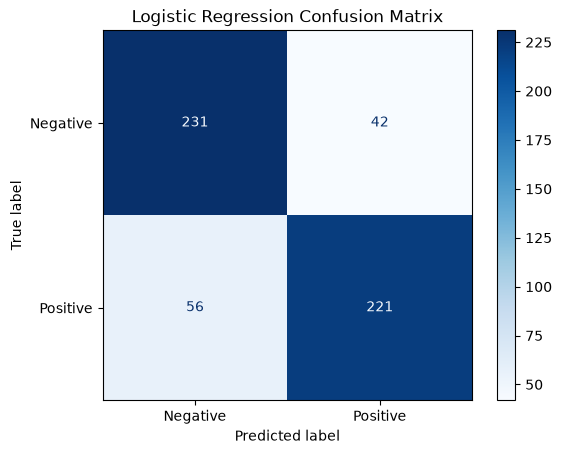

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    lr_predictions,
    display_labels=["Negative", "Positive"],
    cmap="Blues"
)

plt.title("Logistic Regression Confusion Matrix")
plt.show()

In [ ]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "SVM"],
    "Accuracy": [
        accuracy_score(y_test, lr_predictions),
        accuracy_score(y_test, svm_predictions)
    ],
    "Precision": [
        precision_score(y_test, lr_predictions),
        precision_score(y_test, svm_predictions)
    ],
    "Recall": [
        recall_score(y_test, lr_predictions),
        recall_score(y_test, svm_predictions)
    ],
    "F1 Score": [
        f1_score(y_test, lr_predictions),
        f1_score(y_test, svm_predictions)
    ]
})

print(results.round(4))

                 Model  Accuracy  Precision  Recall  F1 Score
0  Logistic Regression    0.8218     0.8403  0.7978    0.8185
1                  SVM    0.8218     0.8303  0.8123    0.8212


In [ ]:
def predict_sentiment(sentence):
    cleaned = clean_text(sentence)
    vectorized = vectorizer.transform([cleaned])

    prediction = lr_model.predict(vectorized)[0]

    if prediction == 1:
        return "Positive"
    else:
        return "Negative"


test_sentences = [
    "This movie is absolutely amazing!",
    "The product quality is terrible.",
    "I really enjoyed the experience.",
    "The customer service was very disappointing.",
    "This is the best purchase I have made."
]

for sentence in test_sentences:
    print("Sentence:", sentence)
    print("Prediction:", predict_sentiment(sentence))
    print("-" * 50)

Sentence: This movie is absolutely amazing!
Prediction: Positive
--------------------------------------------------
Sentence: The product quality is terrible.
Prediction: Negative
--------------------------------------------------
Sentence: I really enjoyed the experience.
Prediction: Positive
--------------------------------------------------
Sentence: The customer service was very disappointing.
Prediction: Negative
--------------------------------------------------
Sentence: This is the best purchase I have made.
Prediction: Positive
--------------------------------------------------
